In [1]:
import pandas as pd

df = pd.read_csv("amazon_reviews.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (4915, 12)

Column names:
['Unnamed: 0', 'reviewerName', 'overall', 'reviewText', 'reviewTime', 'day_diff', 'helpful_yes', 'helpful_no', 'total_vote', 'score_pos_neg_diff', 'score_average_rating', 'wilson_lower_bound']


,Unnamed: 0,reviewerName,overall,reviewText,reviewTime,day_diff,helpful_yes,helpful_no,total_vote,score_pos_neg_diff,score_average_rating,wilson_lower_bound
0,0,NaN,4.0,No issues.,2014-07-23,138,0,0,0,0,0.0,0.0
1,1,0mie,5.0,"Purchased this for my device, it worked as adv...",2013-10-25,409,0,0,0,0,0.0,0.0
2,2,1K3,4.0,it works as expected. I should have sprung for...,2012-12-23,715,0,0,0,0,0.0,0.0
3,3,1m2,5.0,This think has worked out great.Had a diff. br...,2013-11-21,382,0,0,0,0,0.0,0.0
4,4,2&amp;1/2Men,5.0,"Bought it with Retail Packaging, arrived legit...",2013-07-13,513,0,0,0,0,0.0,0.0


In [2]:
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4915 entries, 0 to 4914
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unnamed: 0            4915 non-null   int64  
 1   reviewerName          4914 non-null   object 
 2   overall               4915 non-null   float64
 3   reviewText            4914 non-null   object 
 4   reviewTime            4915 non-null   object 
 5   day_diff              4915 non-null   int64  
 6   helpful_yes           4915 non-null   int64  
 7   helpful_no            4915 non-null   int64  
 8   total_vote            4915 non-null   int64  
 9   score_pos_neg_diff    4915 non-null   int64  
 10  score_average_rating  4915 non-null   float64
 11  wilson_lower_bound    4915 non-null   float64
dtypes: float64(3), int64(6), object(3)
memory usage: 460.9+ KB
None

Missing values:
Unnamed: 0              0
reviewerName            1
overall                 0
reviewText     

In [3]:
# Keep only the columns needed for sentiment analysis
df = df[['reviewText', 'overall']].copy()

# Remove rows with missing review text or rating
df = df.dropna(subset=['reviewText', 'overall'])

# Remove empty reviews
df['reviewText'] = df['reviewText'].astype(str).str.strip()
df = df[df['reviewText'] != '']

# Remove duplicate review texts
df = df.drop_duplicates(subset=['reviewText'])

print("Shape after cleaning:", df.shape)
print("Missing values:\n", df.isnull().sum())

Shape after cleaning: (4912, 2)
Missing values:
 reviewText    0
overall       0
dtype: int64


In [4]:
def get_sentiment(rating):
    if rating <= 2:
        return 0       # Negative
    elif rating == 3:
        return 1       # Neutral
    else:
        return 2       # Positive

df['label'] = df['overall'].apply(get_sentiment)

print(df['label'].value_counts().sort_index())

label
0     324
1     142
2    4446
Name: count, dtype: int64


In [5]:
print(df['label'].value_counts().sort_index())

print("\nPercentage distribution:")
print((df['label'].value_counts(normalize=True) * 100).round(2))

label
0     324
1     142
2    4446
Name: count, dtype: int64

Percentage distribution:
label
2    90.51
0     6.60
1     2.89
Name: proportion, dtype: float64


In [6]:
from sklearn.utils import resample

# Keep the same number of examples from each class
df_balanced = (
    df.groupby('label', group_keys=False)
      .apply(lambda group: resample(
          group,
          n_samples=min(140, len(group)),
          random_state=42
      ))
      .reset_index(drop=True)
)

# Shuffle the rows
df_balanced = df_balanced.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Balanced dataset shape:", df_balanced.shape)
print("\nClass distribution:")
print(df_balanced['label'].value_counts().sort_index())

Balanced dataset shape: (420, 3)

Class distribution:
label
0    140
1    140
2    140
Name: count, dtype: int64


/tmp/ipykernel_4431/3989483693.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: resample(


In [7]:
from sklearn.model_selection import train_test_split

# Input text and target labels
X = df_balanced['reviewText'].astype(str)
y = df_balanced['label']

# First split: 80% training, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: divide the temporary set equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nValidation class distribution:")
print(y_val.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training samples: 336
Validation samples: 42
Testing samples: 42

Training class distribution:
label
0    112
1    112
2    112
Name: count, dtype: int64

Validation class distribution:
label
0    14
1    14
2    14
Name: count, dtype: int64

Testing class distribution:
label
0    14
1    14
2    14
Name: count, dtype: int64


In [9]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Settings
vocab_size = 5000
max_length = 100

# Create tokenizer
tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

# Learn vocabulary from training data only
tokenizer.fit_on_texts(X_train)

# Convert text into sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Make every sequence the same length
X_train_pad = pad_sequences(
    X_train_seq, maxlen=max_length, padding="post", truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq, maxlen=max_length, padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=max_length, padding="post", truncating="post"
)

# Convert labels to integer arrays
import numpy as np

y_train_np = np.array(y_train)
y_val_np = np.array(y_val)
y_test_np = np.array(y_test)

print("Training shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)
print("Testing shape:", X_test_pad.shape)
print("Example sequence:", X_train_pad[0][:20])

Training shape: (336, 100)
Validation shape: (42, 100)
Testing shape: (42, 100)
Example sequence: [   3  156    9   14   10   43  148  545    5  156    7  381   11  109
    5 1595   17    4    3  157]


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Build the LSTM model
lstm_model = Sequential([
    Embedding(input_dim=5000, output_dim=64, input_length=100),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(3, activation='softmax')
])

# Compile the model
lstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model structure
lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_pad,
    y_train_np,
    validation_data=(X_val_pad, y_val_np),
    epochs=15,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - accuracy: 0.4137 - loss: 1.0915 - val_accuracy: 0.4524 - val_loss: 1.0792
Epoch 2/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5030 - loss: 1.0435 - val_accuracy: 0.5000 - val_loss: 1.0330
Epoch 3/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5000 - loss: 0.9912 - val_accuracy: 0.4524 - val_loss: 1.0425
Epoch 4/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5536 - loss: 0.9260 - val_accuracy: 0.5476 - val_loss: 1.0620
Epoch 5/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6071 - loss: 0.9232 - val_accuracy: 0.4286 - val_loss: 1.0565


In [12]:
test_loss, test_accuracy = lstm_model.evaluate(
    X_test_pad,
    y_test_np,
    verbose=0
)

print(f"LSTM Test Loss: {test_loss:.4f}")
print(f"LSTM Test Accuracy: {test_accuracy:.4f}")

LSTM Test Loss: 1.0170
LSTM Test Accuracy: 0.4762


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 652ms/step
              precision    recall  f1-score   support

    Negative       0.64      0.50      0.56        14
     Neutral       0.00      0.00      0.00        14
    Positive       0.42      0.93      0.58        14

    accuracy                           0.48        42
   macro avg       0.35      0.48      0.38        42
weighted avg       0.35      0.48      0.38        42



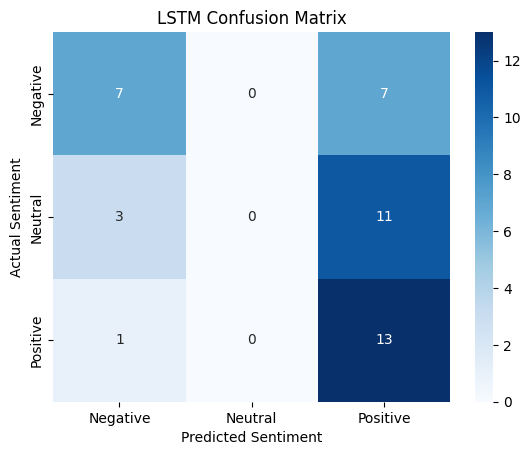

In [13]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Predict sentiment classes
y_pred_prob = lstm_model.predict(X_test_pad)
y_pred = np.argmax(y_pred_prob, axis=1)

# Classification report
print(classification_report(
    y_test_np,
    y_pred,
    labels=[0, 1, 2],
    target_names=['Negative', 'Neutral', 'Positive'],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test_np, y_pred, labels=[0, 1, 2])

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.title('LSTM Confusion Matrix')
plt.show()

In [8]:
#next algorithm Bert
!pip install -q transformers datasets accelerate

In [9]:
from transformers import AutoTokenizer

model_name = "distilbert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Tokenizer loaded successfully!")

Tokenizer loaded successfully!


In [10]:
train_encodings = bert_tokenizer(
    X_train.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

val_encodings = bert_tokenizer(
    X_val.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

test_encodings = bert_tokenizer(
    X_test.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

print("Training reviews:", len(train_encodings["input_ids"]))
print("Validation reviews:", len(val_encodings["input_ids"]))
print("Testing reviews:", len(test_encodings["input_ids"]))

Training reviews: 336
Validation reviews: 42
Testing reviews: 42


In [11]:
import torch
from torch.utils.data import Dataset

class ReviewDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }
        item["labels"] = torch.tensor(
            int(self.labels[idx]),
            dtype=torch.long
        )
        return item


train_dataset = ReviewDataset(train_encodings, y_train)
val_dataset = ReviewDataset(val_encodings, y_val)
test_dataset = ReviewDataset(test_encodings, y_test)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 336
Validation dataset: 42
Testing dataset: 42


In [12]:
from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding
)

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=3,
    id2label={
        0: "NEGATIVE",
        1: "NEUTRAL",
        2: "POSITIVE"
    },
    label2id={
        "NEGATIVE": 0,
        "NEUTRAL": 1,
        "POSITIVE": 2
    }
)

data_collator = DataCollatorWithPadding(
    tokenizer=bert_tokenizer
)

print("DistilBERT model loaded successfully!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully!


In [13]:
print("GPU available:", torch.cuda.is_available())

GPU available: True


In [14]:
from transformers import TrainingArguments, Trainer
import torch

training_args = TrainingArguments(
    output_dir="./sentiment_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=4,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_steps=10,
    report_to="none",
    fp16=torch.cuda.is_available()
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    processing_class=bert_tokenizer
)

print("Trainer configured successfully!")

Trainer configured successfully!


In [15]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,1.007794,1.018892
2,0.808823,0.868664
3,0.588593,0.802197
4,0.509930,0.742199


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=168, training_loss=0.7569795336042132, metrics={'train_runtime': 35.4157, 'train_samples_per_second': 37.949, 'train_steps_per_second': 4.744, 'total_flos': 44509839704064.0, 'train_loss': 0.7569795336042132, 'epoch': 4.0})

DistilBERT Test Accuracy: 0.6190

Classification Report:
              precision    recall  f1-score   support

    Negative       0.67      0.57      0.62        14
     Neutral       0.60      0.43      0.50        14
    Positive       0.60      0.86      0.71        14

    accuracy                           0.62        42
   macro avg       0.62      0.62      0.61        42
weighted avg       0.62      0.62      0.61        42



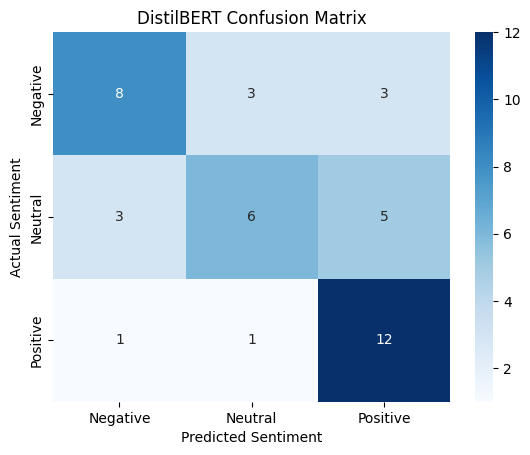

In [16]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Predict on the test dataset
predictions = trainer.predict(test_dataset)

# Get predicted class for each review
y_pred_bert = np.argmax(predictions.predictions, axis=1)

# Actual test labels
y_true = np.array(y_test)

# Calculate accuracy
bert_accuracy = accuracy_score(y_true, y_pred_bert)

print(f"DistilBERT Test Accuracy: {bert_accuracy:.4f}")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred_bert,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred_bert, labels=[0, 1, 2])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("DistilBERT Confusion Matrix")
plt.show()

In [18]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# DistilBERT predictions (already computed in previous cell)
y_pred_bert = np.asarray(y_pred_bert)


def get_metrics(y_true, y_pred, model_name):
  precision, recall, f1, _ = precision_recall_fscore_support(
      y_true, y_pred, average="macro", zero_division=0
  )
  return {
      "Model": model_name,
      "Accuracy": round(accuracy_score(y_true, y_pred), 4),
      "Macro Precision": round(precision, 4),
      "Macro Recall": round(recall, 4),
      "Macro F1": round(f1, 4),
  }


# Generate summary for DistilBERT
results = pd.DataFrame([get_metrics(y_true, y_pred_bert, "DistilBERT")])

display(results)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,DistilBERT,0.619,0.6222,0.619,0.6071


In [19]:
# Save comparison results as a CSV file
results.to_csv("model_comparison.csv", index=False)

print("Comparison results saved successfully!")
display(results)

Comparison results saved successfully!


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,DistilBERT,0.619,0.6222,0.619,0.6071
